# Model Evaluation Techniques for Multiple Linear Regression (MLR)

## Why Model Evaluation?

Model evaluation helps us measure how well our regression model predicts the target variable.

Even if the model looks good, we need metrics to assess **accuracy**, **error**, and **explanatory power**.


## Common Evaluation Metrics for MLR

### 1️⃣ R² Score (Coefficient of Determination)

#### 🔍 Concept:
R² tells us what percentage of the variation in the target variable is explained by the model.

**R² Formula:**

R² = 1 − ( Σ(yi − ŷi)² / Σ(yi − ȳ)² )

Where:
- yi = Actual value
- ŷi = Predicted value
- ȳ = Mean of actual values


## R² Calculation – Example

**Mean of actual values:**

ȳ = (10 + 15 + 18) / 3 = 14.33

**SSres (Sum of Squared Residuals):**

(10 − 12)² + (15 − 14)² + (18 − 16)² = 4 + 1 + 4 = 9

**SStotal (Total Sum of Squares):**

(10 − 14.33)² + (15 − 14.33)² + (18 − 14.33)² ≈ 18.78 + 0.44 + 13.44 = 32.66

**R² Calculation:**

R² = 1 − ( SSres / SStotal ) = 1 − ( 9 / 32.66 ) ≈ 0.7245


# PYTHON CODE

In [2]:
from sklearn.metrics import r2_score

actual = [10, 15, 18]
pred = [12,14,16]
print("R² : ", r2_score(actual, pred))
# Higher R² is always better

R² :  0.7244897959183674


### 2️⃣ RMSE (Root Mean Squared Error)

#### 📐 RMSE Formula:

RMSE = √(1/n) Σ(yi − ŷi)² )

Where:
- yi = Actual value
- ŷi = Predicted value
- n = Number of observations


### 📊 Example: RMSE Calculation

Using the same example:
- Actual values: [10, 15, 18]
- Predicted values: [12, 14, 16]

We already calculated the sum of squared errors:

MSE = ( (10 − 12)² + (15 − 14)² + (18 − 16)² ) / 3 = 9 / 3 = 3

Now calculate RMSE:

RMSE = √3 ≈ 1.732


# PYTHON CODE

In [4]:
from sklearn.metrics import mean_squared_error
import numpy as np

actual = [10,15,18]
pred = [12,14,16]

rmse = np.sqrt(mean_squared_error(actual, pred))
print("RMSE:", round(rmse, 3))
#Lower the rmse the better bcoz its an error

RMSE: 1.732


### 📊 Example: MAE (Mean Absolute Error)

Let's continue with the same example:
- Actual values: [10, 15, 18]
- Predicted values: [12, 14, 16]

Calculate absolute errors:
- |10 − 12| = 2
- |15 − 14| = 1
- |18 − 16| = 2

Now compute MAE:

MAE = (2 + 1 + 2) / 3 = 5 / 3 ≈ 1.67


# PYTHON CODE

In [5]:
from sklearn.metrics import mean_absolute_error
actual = [10,15,18]
pred = [12,14,16]
mae = mean_absolute_error(actual, pred)
print("MAE:", round(mae,2))

MAE: 1.67


### 📊 Example: MAPE (Mean Absolute Percentage ErrorSame data:
- Actual: [10, 15, 18]
- Predicted: [12, 14, 16]

Step-by-step percentage errors:
- |10 − 12| / 10 = .20

- |15 − 14| /15 = 0.0667

- |18 − 16| / 18 = 0.1111```

MAPE = (0.20 + 0.0667 + 0.1111) / 3 × 100 ≈ 12.59%



In [10]:
### 🐍 Python Code:

actual = np.array([10, 15, 18])
pred = np.array([12, 14, 16])

mape = np.mean(np.abs((actual - pred) / actual)) * 100
print("MAPE:", round(mape, 2), "%")
#12% away from average

MAPE: 12.59 %


| Metric | What it Measures | Ideal Value | Use Case |
|--------|------------------|-------------|----------|
| R²   | % variance explained | Closer to 1 | Model fit quality |
 RMSE | squared error | Closer to 0 | Penalizes large errors |
| MAE  | Average absolute error | Closer to 0 | Simpler error interpretation |
| MAPE | Avg % error from actuals | Lower % | Explaining % error to audience |


## ✅ Final Notes:

- Always evaluate the model on **test data**
- Use **multiple metrics** to get a complete picture
- RMSE penalizes large errors more; MAE is easier to explain
- R² shows explanatory power, not accuracy

> Use these metrics to select and justify your regression model before making business decisions or deployment.


## 🎓 What is a Residual Plot?

A residual is the difference between the actual value and the predicted value:

## 📐 Residual Formula

**Residual = y_actual − y_predicted**

A residual plot is a graph that shows:

- **x-axis** → predicted values
- **y-axis** → residuals (errors)


## ✅ What Does a Good Residual Plot Look Like?

- Residuals should be **randomly scattered** around the horizontal line at **0**.
- No clear pattern should be visible.
- This means: your model's errors are **evenly distributed** → a sign of a **good fit**.

## ⚠️ Why It's Important

If your residuals do **not** look random:

- 📩 You may have **missed a pattern** in the data.
- ✏️ If residuals increase/decrease systematically, it may mean:
  - You're missing a **nonlinear relationship**.
  - Your model may be **underfitting or overfitting**.


## 📉 If Residuals Show a Systematic Pattern…

### 🔍 What It Indicates:

A clear curve, slope, or funnel shape in the residuals means your model is violating key assumptions of linear regression — especially **linearity** and **homoscedasticity** (constant variance).

This usually points to:

- A **nonlinear relationship** that linear regression can't capture
- **Missing variables** or interactions in the model
- Possible **underfitting**


## 🛠️ What You Can Do to Fix It

### 1. ✅ Add Polynomial Terms

If the residuals follow a curved pattern (U-shape or inverted U), it means the relationship is nonlinear.

📌 **Fix:** Try a Polynomial Regression model


In [14]:
# from sklearn.preprocessing import PolynomialFeatures
# from sklearn.linear_model import LinearRegression
# from sklearn.pipeline import make_pipeline

# poly_model = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
# poly_model.fit(X_train, y_train)

### 2. ✅ Apply Feature Transformation 🧪

If residuals increase or decrease systematically, apply transformations like:

 **Log** or **sqrt** for right-skewed variables- **Box-Cox** for automatic transformation (scipy)

📌 **Fix:** Example using log transformation

In [15]:
#df['TV_Radio'] = df['TV'] * df['Radio']

### 3. ✅ Add Missing Features or Interaction Terms 🔗

Sometimes model misses important variables or their interactions.

📌 **Fix:** Add interaction manually


### 4. ✅ Use a More Flexible Model 🌲

If linear regression is still struggling:

 Try **Decision Trees**, **Random Forests**, or **Gradient Boosting**
- These handle **nonlinearities** and **interactions** automatically

In [18]:
# df['log_variable'] = np.log(df['original_variable'] + 1 )

## 📝 Note

If your residuals show a **curved pattern** or **increase with predictions**, your model is likely missing something.

You can fix this by **adding polynomial terms**, **transforming variables**, or **switching to a nonlinear model**.

Residual plots aren't just diagnostic — they **guide how to improve the model**.


## 🎯 If Residuals Suggest Underfitting or Overfitting

Here's how to detect and fix each:

---

### 🔻 Underfitting

**Clues:- Residuals show a clear pattern (e.g., curve, slope)
- R² is low on both training and test
- Model is too simple to capture true data structure

**Common Causes:**
- Using only linear terms when the relationship is nonlinear
- Leaving out important features

**Remedies:**
- ✅ Add polynomial features (e.g., degree 2 or 3)
- ✅ Include interaction terms
- ✅ Apply log/sqrt transformations
- ✅ Switch to a more complex model (e.g., decision tree)


### 🔺 Overfitting

**Clues:**
- Residuals look random on training data, but prediction errors are high on test data
- High R² on training, low R² on test
- Too many predictors or overly complex model

**Common Causes:**
- Model memorizes noise instead of generalizing patterns

**Remedies:**
- ✅ Simplify the model (remove unnecessary features)
- ✅ Use regularization: Ridge or Lasso regression
- ✅ Apply cross-validation to detect overfitting early
- ✅ Gather more data if possible


# 📊 Linear Regression Deep Dive: From Simple to Multiple

**Subtitle:** Comparing OLS (Statsmodels) and Scikit-learn, Then Scaling to MLR


In [1]:
# Topics outline

# Comparision between OLS and SciKit-Learn

# Multiple linear regression model

# What is VIF (Variance Inflation Factor)


### 🔹 Comparison between two approach OLS (Ordinary Least Square) vs Scikit-learn (Simple Linear Regression)

| Aspect | OLS (statsmodels) | Scikit-learn |
|---|---|---|
| **Ease of Use** | Requires adding an intercept manually | Automatically handles intercept |
| **Best For** | Learning how regression works | Building real-world models quickly |
| **Output** | Detailed report (p-values, R², etc.) | Only coefficients and R² |
| **Speed** | Slower for huge datasets | Faster for big data |
| **Extra Features** | ❌ Just regression | ✅ Works with other ML (scalers) |


### 🔹 Introduction to Multiple Linear Regression (MLR)

In **Simple Linear Regression**, we had:

- **One input → One output**

Now, in **Multiple Linear Regression**, we move to:

- **Multiple inputs → One output**


### 🔹 Multiple Linear Regression Equation:

**y = β₀ + β₁x₁ + β₂x₂ + ⋯ + βₙxₙ**

- **y**: Target variable (what we want to predict)
- **x₁, x₂, …, xₙ**: Input features
- **β₀**: Intercept (bias term)
- **β₁ to βₙ**: Coefficients for each feature


### 💡 Real-world Use Cases:

➡️ **MLR is the natural extension of Simple Linear Regression and forms the base of many advanced machine learning models.**

- 🎓 **Education**: Predict student performance using:
  - Hours studied
  - Class attendance
  - Prior GPA
- 🏥 **Healthcare**: Predict recovery time using:
  - Age
  - Time to treatment
  - Heart rate


### 🔹 Features

- Features are the **input variables** used to make predictions.
- In **Multiple Linear Regression**, we use **two or more features** to predict a **single target**.

**Examples:**
- 📚 Hours, Studied, Attendance, and GPA to predict **Final_Score**
- 📺 TV, Radio, and Newspaper to predict **Sales**


### 🔹 Coefficients (β₁, β₂, …, βₙ)

- Each coefficient shows **how much that feature contributes** to the prediction — **holding other features constant**.

**Example:**
- 💡 If **β₁ = 0.45 for Hours_Studied**, then for every extra hour studied,
- the final score **increases by 0.45 points**, assuming all other features remain the same.


### 🔹 Multicollinearity

- When **two or more features are highly correlated**, they can confuse the model. This is called **multicollinearity**.

**Why it's risky:**
- ⚠️ The model may give **unreliable coefficients**
- ⚠️ It becomes **harder to interpret** which feature is really important

**Example:**
- 📌 If both **Education_Level** and **Years_of_Schooling** are used, they might convey the **same info**.


### 📈 Multiple Linear Regression Model :- Predicting sales based on advertising on TV, Radio, Newspaper 📰


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error , r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data = pd.read_csv("advertising.csv")
# Display the first few rows of the dataset
data.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [5]:
data.shape

(200, 4)

In [7]:
data.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

# Define the independent variables(X) and the dependent variables (Y)

In [10]:
x = data[['TV' , 'Radio', 'Newspaper']] # predictors , independent variable
y = data['Sales'] #target variable, dependent variable

In [11]:
x.head()

,TV,Radio,Newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


In [12]:
y.head()

0    22.1
1    10.4
2    12.0
3    16.5
4    17.9
Name: Sales, dtype: float64

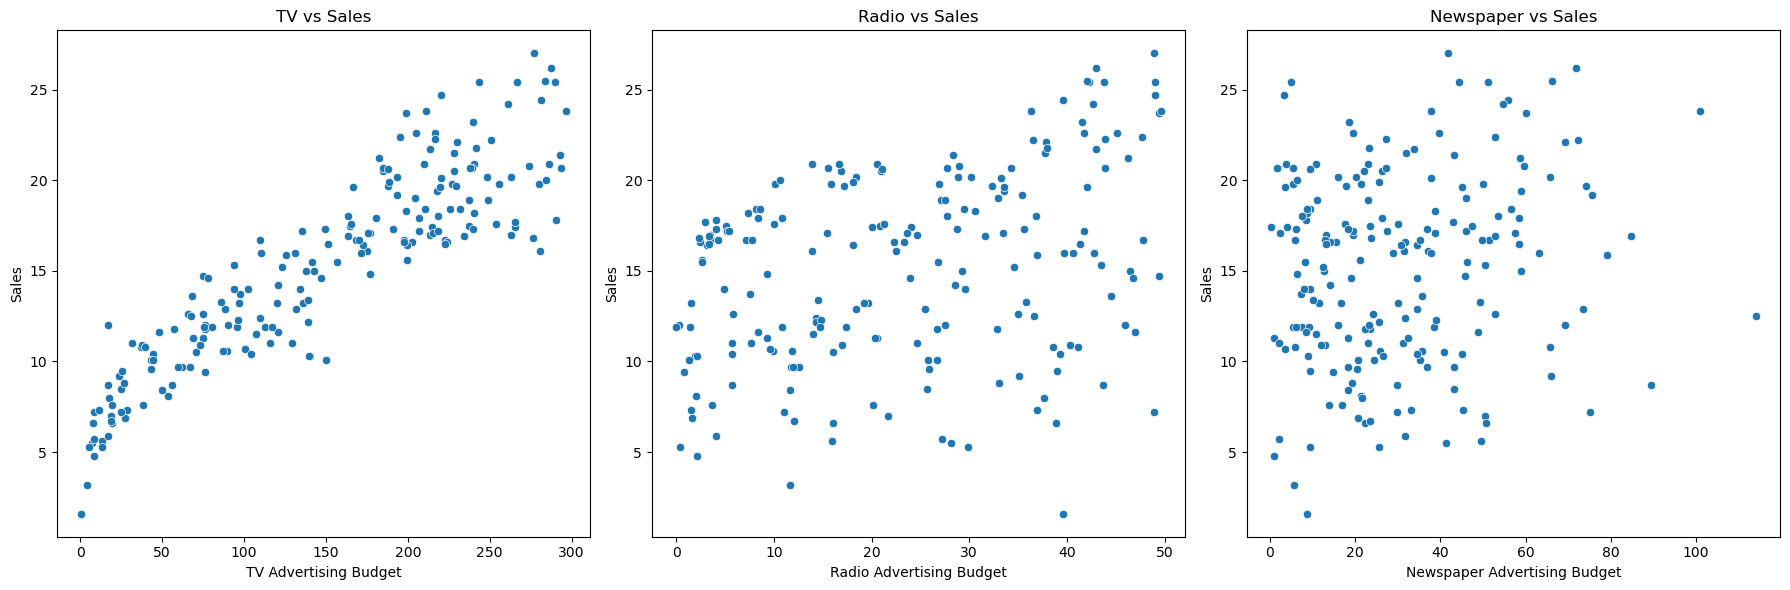

In [13]:
# Plotting scatter plots
plt.figure(figsize = (18,6))
# Scatter plot for TV vs Sales
plt.subplot(1,3,1)
sns.scatterplot(x = data['TV'], y = data['Sales'])
plt.title('TV vs Sales')
plt.xlabel('TV Advertising Budget')
plt.ylabel('Sales')

# Scatter plot for Radio vs Sales
plt.subplot(1,3,2)
sns.scatterplot(x = data['Radio'], y = data['Sales'])
plt.title('Radio vs Sales')
plt.xlabel('Radio Advertising Budget')
plt.ylabel('Sales')

# Scatter plot for Newspaper vs Sales
plt.subplot(1,3,3)
sns.scatterplot(x = data['Newspaper'], y = data['Sales'])
plt.title('Newspaper vs Sales')
plt.xlabel('Newspaper Advertising Budget')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()

In [14]:
# Check any of predictor(x) is co-related to another predictor(x)

In [15]:
x.corr()

,TV,Radio,Newspaper
TV,1.000000,0.054809,0.056648
Radio,0.054809,1.000000,0.354104
Newspaper,0.056648,0.354104,1.000000


# Compute the correlation matrix

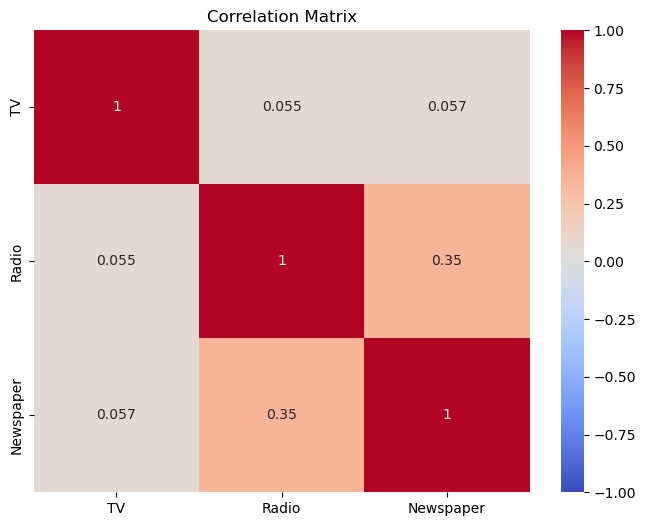

                 TV     Radio  Newspaper
TV         1.000000  0.054809   0.056648
Radio      0.054809  1.000000   0.354104
Newspaper  0.056648  0.354104   1.000000


In [16]:
correlation_matrix = x.corr()
# Plot the correlation matrix
plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix, annot = True, cmap = 'coolwarm', vmin = -1, vmax = 1)
plt.title('Correlation Matrix')
plt.show()
# Display the correlation matrix
print(correlation_matrix)

### 🔹 What is VIF (Variance Inflation Factor)?

**VIF** measures **how much the variance of a regression coefficient is inflated due to multicollinearity among input features**.


### 🔹 Why is VIF Important in MLR?

In Multiple Linear Regression, we use multiple features to predict a single target. Sometimes, two or more features are **strongly correlated** with each other (e.g., `Education_Level` and `Years_of_Schooling`).

This creates **multicollinearity**, which makes it hard for the model to learn the true contribution of each feature — it may **inflate variance** and reduce the model's ability to generalize.


### 🔹 What VIF Tells You:

| VIF Score | Interpretation |
|-----------|----------------|
| 1 | No multicollinearity (ideal) |
| 1 - 5 | Moderate multicollinearity (acceptable) |
| > 5 or 10 | High multicollinearity (potential problem) |


### 🔹 When You Don't Use VIF

**If your model might not run, but:**
- Coefficients become unstable
- You may get wrong signs on values (e.g., β is negative when it should be positive)
- Model might fit well but **R²** is misleading

**Example 🍝:**
- "VIF is like checking if ingredients in a recipe are too similar — like flour, you don't really need both"


In [17]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
#Calculate the VIF for each feature
vif_data = pd.DataFrame()
vif_data['feature'] = x.columns
vif_data['VIF'] = [variance_inflation_factor(x.values, i) for i in range(x.shape[1])]
print("Variance Inflation Factors (VIF)")
print(vif_data)

Variance Inflation Factors (VIF)
     feature       VIF
0         TV  2.486772
1      Radio  3.285462
2  Newspaper  3.055245


### 🔹 What to Do If Multicollinearity is Detected?

1. **Remove Variables** — Consider removing one of the correlated variables
2. **Combine Variables** — Combine correlated variables into a single predictor
3. **Regularization Techniques** — Use techniques like **Ridge Regression** or **Lasso Regression**, which handle multicollinearity by adding a penalty to the coefficients


# Split the data into training and testing sets

In [18]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size = 0.3, random_state = 42)

In [21]:
x_train.shape

(140, 3)

In [22]:
y_train.shape

(140,)

In [23]:
x_test.shape , y_test.shape

((60, 3), (60,))

# Create and train the linear regression model

In [24]:
linear_model = LinearRegression()
linear_model.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


# Make predictions

In [25]:
y_test_pred = linear_model.predict(x_test) 

In [26]:
# Create DataFrame for testing data

In [27]:
y_test_pred

array([17.15991908, 20.53369503, 23.68914396,  9.5191455 , 21.60736836,
       12.78101318, 21.08636345,  8.76054246, 17.11499951, 16.68789636,
        8.97584663,  8.57645026, 18.33212325,  8.17863567, 12.64605571,
       14.94486946,  8.34939536, 17.83858948, 11.12172174, 20.37740648,
       20.9483297 , 13.04035779, 11.01360656, 22.51142595,  9.40369784,
        7.98591291, 20.86943368, 13.77882255, 10.83407064,  8.00419229,
       15.88597618, 10.7027424 , 20.9521718 , 10.84679243, 21.50720813,
       21.07347295, 12.22673775, 22.85273767, 12.57698182,  6.54597206,
       11.93411853, 15.23490068, 10.07411153,  9.52159696, 17.11786382,
        7.28032677, 10.49404864, 15.24356754, 11.20742176, 11.78392665,
       14.01472163, 14.59884572, 10.82722434,  9.55839415,  9.03749681,
       12.51183313, 10.52551021, 25.01900824,  7.99334943, 15.73916263])

In [29]:
y_test

95     16.9
15     22.4
30     21.4
158     7.3
128    24.7
115    12.6
69     22.3
170     8.4
174    16.5
45     16.1
66     11.0
182     8.7
165    16.9
78      5.3
186    10.3
177    16.7
56      5.5
152    16.6
82     11.3
68     18.9
124    19.7
16     12.5
148    10.9
93     22.2
65     11.3
60      8.1
84     21.7
67     13.4
125    10.6
132     5.7
9      15.6
18     11.3
55     23.7
75      8.7
150    16.1
104    20.7
135    11.6
137    20.8
164    11.9
76      6.9
79     11.0
197    14.8
38     10.1
24      9.7
122    16.6
195     7.6
29     10.5
19     14.6
143    10.4
86     12.0
114    14.6
173    16.7
5       7.2
126     6.6
117     9.4
73     11.0
140    10.9
98     25.4
172     7.6
96     16.7
Name: Sales, dtype: float64

In [30]:
test_results = pd.DataFrame({
    'Original Sales (Test)' : y_test,
    'Predicted Sales (Test)' : y_test_pred
})
# Display the first few rows of the testing results
print("Testing Data Results")
print(test_results.head())

Testing Data Results
     Original Sales (Test)  Predicted Sales (Test)
95                    16.9               17.159919
15                    22.4               20.533695
30                    21.4               23.689144
158                    7.3                9.519146
128                   24.7               21.607368


### 🔹 Summary

- Comparison between **OLS** and **Scikit-Learn**
- **Multiple Linear Regression** model
- What is **VIF (Variance Inflation Factor)**
